Un modelo predictivo ampliamente usado es la regresión lineal, que en términos generales se trata de que, con ayuda de información histórica (datos de entrenamiento) predecir un resultado. Posiblemente en el transcurso de una auditoría hayas escuchado de que la empresa auditada para fines de cierre contable estima ingresos o egresos, y aunque el monto estimado es reversado/ajustado en el cierre posterior ingresando el monto real, esta práctica es cuando menos criticable por el método generalmente utilizado: tomar el dato real de tres meses anteriores, dividirlo entre tres y listo ese es el dato estimado... ¿que pasa con el registro estimado de diciembre = cierre de año?, ¿es cercano a lo real?, ¿es cuando menos una forma reconocida y válida para hacerlo?.

Este notebook sirve para introducir la idea de utilizar modelos predictivos más robustos, el escenario es simple: una organización se está preparando para el cierre anual y necesita predecir, con bases sólidas, el ingreso que tendrá en el mes de diciembre. Lo ideal sería que tomara suficiente información para tomar en cuenta estacionalidad, pero el ejemplo será muy simple, tomará el dato real de ingresos del periodo enero - noviembre para estimar el monto de ingresos para el mes de diciembre.  

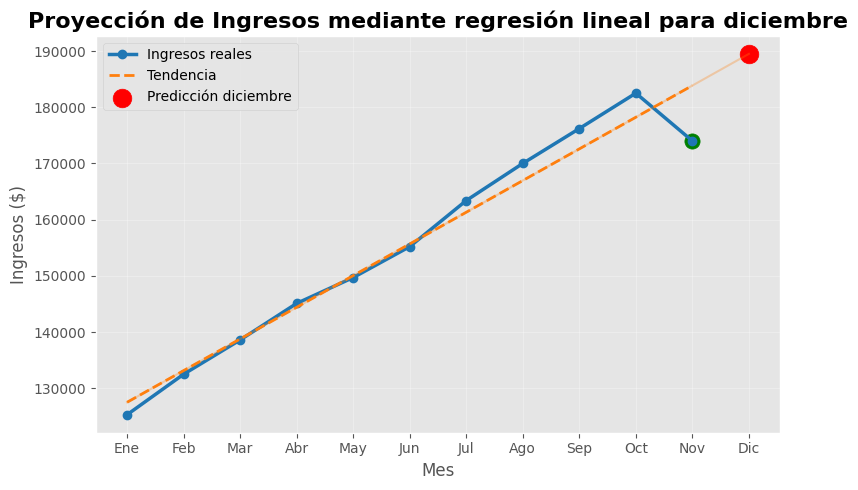

Ingreso estimado para diciembre: $189,489.09


In [1]:
# importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# datos históricos
datos = {
    'Mes': ['Ene','Feb','Mar','Abr','May','Jun',
            'Jul','Ago','Sep','Oct','Nov'],
    'Ingresos': [125_300,132_500,138_600,145_100,149_700,
                 155_200,163_400,170_000,176_200,182_500,174_000]
}

df = pd.DataFrame(datos)

# variable independiente
X = np.arange(1, len(df)+1).reshape(-1,1)

# variable dependiente
y = df['Ingresos']

# modelo
modelo = LinearRegression()
modelo.fit(X,y)

# predicción diciembre
diciembre = np.array([[12]])
pred_dic = modelo.predict(diciembre)[0]

# tabla de resultados
tabla = df.copy()
tabla.loc[len(tabla)] = ['Dic (Estimado)', round(pred_dic)]

# mostrar la tabla
tabla

# valores ajustados
y_pred = modelo.predict(X)

# gráfica para visualizar los resultados y la predicción
plt.figure(figsize=(8,5))

plt.plot(df['Mes'],
         df['Ingresos'],
         marker='o',
         linewidth=2.5,
         color='#1f77b4',
         label='Ingresos reales')

plt.plot(df['Mes'],
         y_pred,
         linestyle='--',
         linewidth=2,
         color='#ff7f0e',
         label='Tendencia')

plt.scatter('Nov',
            df['Ingresos'].iloc[-1],
            color='green',
            s=120)

plt.scatter('Dic',
            pred_dic,
            color='red',
            s=180,
            label='Predicción diciembre')

meses = list(df['Mes']) + ['Dic']

plt.plot(meses,
         list(y_pred) + [pred_dic],
         color='#ff7f0e',
         alpha=0.3)

plt.title('Proyección de Ingresos mediante regresión lineal para diciembre',
          fontsize=16,
          fontweight='bold')

plt.xlabel('Mes')
plt.ylabel('Ingresos ($)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

print(f"Ingreso estimado para diciembre: ${pred_dic:,.2f}")

¿que hubiera pasado si el cálculo se hubiera hecho sobre los tres últimos meses? R= (176,200 +182,500 + 174,000) / 3 = $177,566.66, lo cual difiere bastante contra lo que muestra el script, la tendencia es positiva aún cuando noviembre presentó un decremento.

¿era necesario usar python? No, en absoluto. Esta es una de esas veces que Excel es más que suficiente para efectuar esta tarea:

<img src="images/lineal.png" alt="lineal" title="lineal" width="700">